# 01 · แถวดิบ 2 Hz

feature = ค่ากล้องและประตูของแถวนั้น ๆ ไม่มีประวัติ (baseline) ตัด warm-up 3 นาทีแรก (360 แถว)

ทุกโมเดลใช้ Pipeline เดียวกัน: `SimpleImputer(median) → StandardScaler → classifier`

In [1]:
import numpy as np, pandas as pd
train = pd.read_csv("../../data/train.csv")   # วันที่ 1–3
test = pd.read_csv("../../data/test.csv")     # วันที่ 4

In [2]:
def prep(df):
    df = df[~((df.boot == 0) & (df.groupby(["day", "boot"]).cumcount() < 360))]
    return df.assign(person_count=df.person_count.where(df.person_count >= 0))   # -1 -> NaN

tr, te = prep(train), prep(test)
F = ["person_count", "digital_do", "analog_2_raw"]
Xtr, ytr, days = tr[F], tr.power_on, tr.day
Xte, yte = te[F], te.power_on
Xtr.shape, Xte.shape

((63707, 3), (21237, 3))

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score
from sklearn.metrics import f1_score, recall_score, precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "DecisionTree": DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, class_weight="balanced", random_state=0),
    "RandomForest": RandomForestClassifier(50, max_depth=6, min_samples_leaf=5, class_weight="balanced", random_state=0, n_jobs=-1),
    "KNN": KNeighborsClassifier(15),
    "GaussianNB": GaussianNB(),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_depth=4, class_weight="balanced", random_state=0),
}
res, preds = [], {}   # preds = ผลทำนาย test ของแต่ละโมเดล (ใช้ใน 05_compare)
for name, clf in models.items():
    pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("clf", clf)])
    # เลือกโมเดลด้วย leave-one-day-out บน train เท่านั้น ส่วน test (วันที่ 4) ดูครั้งเดียว
    cv = cross_val_score(pipe, Xtr, ytr, groups=days, cv=LeaveOneGroupOut(), scoring="f1")
    p = preds[name] = pipe.fit(Xtr, ytr).predict(Xte)
    res.append(dict(model=name, cv_f1=cv.mean(), test_f1=f1_score(yte, p),
                    test_recall=recall_score(yte, p), test_precision=precision_score(yte, p)))
res = pd.DataFrame(res).sort_values("cv_f1", ascending=False).round(4)
res

,model,cv_f1,test_f1,test_recall,test_precision
4,GaussianNB,0.9489,0.9496,0.9487,0.9505
0,LogisticRegression,0.9481,0.9486,0.9464,0.9507
1,DecisionTree,0.9475,0.8517,0.9813,0.7524
5,HistGradientBoosting,0.9472,0.8526,0.9803,0.7544
2,RandomForest,0.9470,0.8525,0.9800,0.7544
3,KNN,0.9467,0.8497,0.9835,0.7479


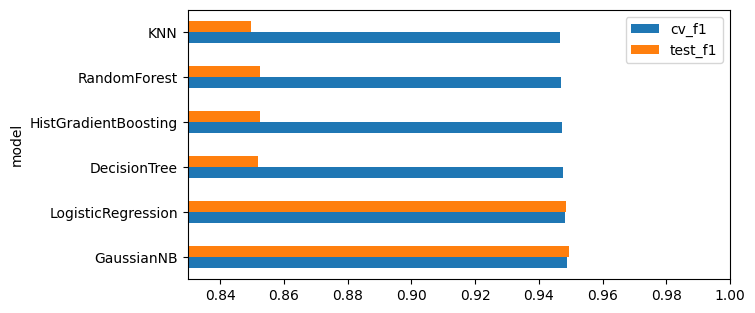

In [4]:
res.set_index("model")[["cv_f1", "test_f1"]].plot.barh(figsize=(7, 3.5), xlim=(res[["cv_f1", "test_f1"]].min().min() - 0.02, 1));